# Machine Learning Assignment 2 – Bank Marketing Classification

This notebook implements the assignment workflow:

1. Load and explore the Bank Marketing dataset.
2. Preprocess numerical and categorical features.
3. Split the data into training and testing sets.
4. Train the five required classifiers.
5. Calculate Accuracy, AUC, Precision, Recall, F1 and MCC.
6. Save all trained pipelines and the held-out test CSV.
7. Generate a Streamlit application file (`app.py`) for deployment.

**Dataset:** UCI Bank Marketing `bank-full.csv` (semicolon-separated).  
**Target:** `y` (`yes` / `no`).

Download the dataset from the [UCI Bank Marketing page](https://archive.ics.uci.edu/dataset/222/bank+marketing), extract `bank-full.csv`, and place it in the same folder as this notebook.

Run the cells from top to bottom. The notebook does not retrain models when the Streamlit app is used.


## 1. Import libraries and set project paths

In [6]:
# If needed, uncomment and run this installation cell:
# %pip install -U streamlit scikit-learn pandas numpy matplotlib seaborn joblib
# %pip install --upgrade jinja2

In [7]:
from pathlib import Path
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    classification_report
)

PROJECT_DIR = Path.cwd()
DATASET_PATH = PROJECT_DIR / "bank-full.csv"
MODEL_DIR = PROJECT_DIR / "model"
TEST_DATA_PATH = PROJECT_DIR / "test_data.csv"
METRICS_PATH = PROJECT_DIR / "model_comparison.csv"
TARGET_COLUMN = "y"
POSITIVE_LABEL = "yes"
NEGATIVE_LABEL = "no"

MODEL_DIR.mkdir(exist_ok=True)
print("Project folder:", PROJECT_DIR)


Project folder: c:\Users\ASUS\Desktop\ML Assignment


## 2. Load the dataset

In [8]:
# The official bank-full.csv file is semicolon-separated.
# If your CSV uses commas, change sep=";" to sep=",".

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATASET_PATH}. Download bank-full.csv from UCI "
        "and place it in the same folder as this notebook."
    )

df = pd.read_csv(DATASET_PATH, sep=";")

# If the file was saved as comma-separated instead:
if df.shape[1] == 1:
    df = pd.read_csv(DATASET_PATH)

df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(str).str.strip().str.lower()

print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully.
Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Explore the dataset

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB

Missing values in each column:


,Missing values
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0



Target class counts:


y
no     39922
yes     5289
Name: count, dtype: int64

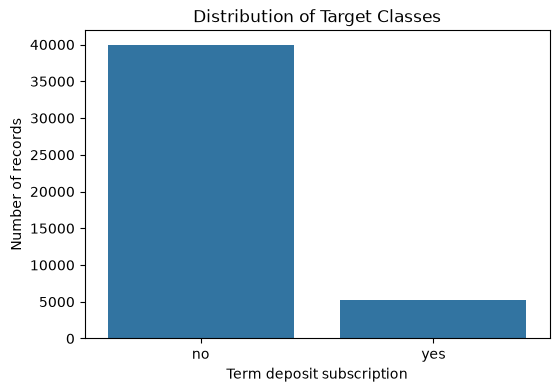

Number of instances: 45211
Number of input features: 16


In [9]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing values"))

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nTarget class counts:")
display(df[TARGET_COLUMN].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET_COLUMN)
plt.title("Distribution of Target Classes")
plt.xlabel("Term deposit subscription")
plt.ylabel("Number of records")
plt.show()

print("Number of instances:", len(df))
print("Number of input features:", df.drop(columns=[TARGET_COLUMN]).shape[1])


## 4. Separate features and target, then split the data

- `X` contains the input features.
- `y` contains the class to predict.
- We use an 80/20 train-test split.
- `stratify=y` preserves the class proportions in both subsets.

The test set is held out for final evaluation. Preprocessing is fitted only on training data through each pipeline, preventing data leakage.


In [10]:
X = df.drop(columns=[TARGET_COLUMN]).copy()
y = df[TARGET_COLUMN].copy()

if X.shape[1] < 12 or len(df) < 500:
    raise ValueError("Dataset must contain at least 12 input features and 500 instances.")

if not set(y.unique()).issubset({NEGATIVE_LABEL, POSITIVE_LABEL}):
    raise ValueError("Expected target labels 'yes' and 'no' in column y.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).rename("proportion"))
print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).rename("proportion"))


Training feature shape: (36168, 16)
Testing feature shape: (9043, 16)

Training target distribution:


y
no     0.883018
yes    0.116982
Name: proportion, dtype: float64


Testing target distribution:


y
no     0.883003
yes    0.116997
Name: proportion, dtype: float64

## 5. Build preprocessing and classifier pipelines

Numerical columns are standardized using `StandardScaler`. Categorical columns are converted to numeric indicator columns using `OneHotEncoder`.

Each classifier is placed in a pipeline with its own preprocessor. This ensures transformations are learned from the training split only. Dense one-hot output is used because `GaussianNB` requires dense input.


In [11]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [
    col for col in X_train.columns if col not in numeric_features
]

def make_preprocessor():
    transformers = []

    if numeric_features:
        transformers.append(
            ("numeric", StandardScaler(), numeric_features)
        )

    if categorical_features:
        transformers.append(
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                categorical_features
            )
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        verbose_feature_names_out=False
    )

classifiers = {
    "Logistic Regression": LogisticRegression(
        max_iter=1500, class_weight="balanced", random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, class_weight="balanced"
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5, weights="uniform"),
    "Naive Bayes": GaussianNB(),
    "SVM": CalibratedClassifierCV(
    estimator=SVC(
        kernel="linear",
        class_weight="balanced",
        random_state=42
    ),
    method="sigmoid",
    cv=3
)
}

pipelines = {
    name: Pipeline([
        ("preprocessing", make_preprocessor()),
        ("classifier", classifier)
    ])
    for name, classifier in classifiers.items()
}

print("Pipelines prepared:", list(pipelines.keys()))


Pipelines prepared: ['Logistic Regression', 'Decision Tree', 'KNN', 'Naive Bayes', 'SVM']


## 6. Train the five models and calculate all six metrics

In [12]:
def evaluate_classifier(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)

    class_labels = list(model.classes_)
    positive_index = class_labels.index(POSITIVE_LABEL)
    y_binary = (y_eval == POSITIVE_LABEL).astype(int)

    return {
        "Accuracy": accuracy_score(y_eval, predictions),
        "AUC": roc_auc_score(y_binary, probabilities[:, positive_index]),
        "Precision": precision_score(
            y_eval, predictions, pos_label=POSITIVE_LABEL, zero_division=0
        ),
        "Recall": recall_score(
            y_eval, predictions, pos_label=POSITIVE_LABEL, zero_division=0
        ),
        "F1": f1_score(
            y_eval, predictions, pos_label=POSITIVE_LABEL, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_eval, predictions)
    }

results = []

for model_name, model in pipelines.items():
    print(f"Training {model_name} ...")
    model.fit(X_train, y_train)

    metric_values = evaluate_classifier(model, X_test, y_test)
    metric_values["Model"] = model_name
    results.append(metric_values)

    filename = model_name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(model, MODEL_DIR / filename)
    print(f"Saved: {MODEL_DIR / filename}")

results_df = pd.DataFrame(results)[
    ["Model", "Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
]

print("Model comparison (actual test-set results):")
display(results_df.style.format({
    "Accuracy": "{:.4f}", "AUC": "{:.4f}", "Precision": "{:.4f}",
    "Recall": "{:.4f}", "F1": "{:.4f}", "MCC": "{:.4f}"
}))

results_df.to_csv(METRICS_PATH, index=False)
print("Metrics saved to:", METRICS_PATH)


Training Logistic Regression ...
Saved: c:\Users\ASUS\Desktop\ML Assignment\model\logistic_regression.joblib
Training Decision Tree ...
Saved: c:\Users\ASUS\Desktop\ML Assignment\model\decision_tree.joblib
Training KNN ...
Saved: c:\Users\ASUS\Desktop\ML Assignment\model\knn.joblib
Training Naive Bayes ...
Saved: c:\Users\ASUS\Desktop\ML Assignment\model\naive_bayes.joblib
Training SVM ...
Saved: c:\Users\ASUS\Desktop\ML Assignment\model\svm.joblib
Model comparison (actual test-set results):


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8457,0.9079,0.4182,0.8147,0.5527,0.5092
1,Decision Tree,0.8796,0.6961,0.4845,0.4565,0.4701,0.4024
2,KNN,0.8962,0.8277,0.5990,0.3403,0.4340,0.4001
3,Naive Bayes,0.8548,0.8101,0.4059,0.5198,0.4559,0.3774
4,SVM,0.8999,0.9076,0.6393,0.3318,0.4368,0.4132


Metrics saved to: c:\Users\ASUS\Desktop\ML Assignment\model_comparison.csv


## 7. Compare the models visually

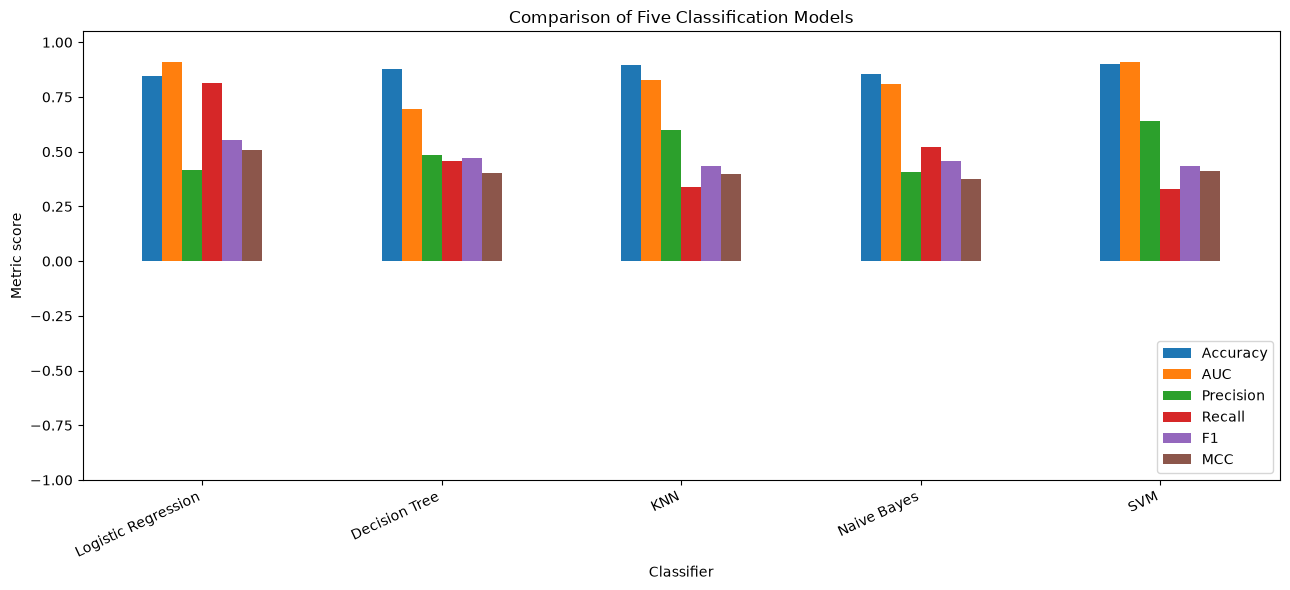

In [13]:
plot_data = results_df.set_index("Model")[
    ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
]

ax = plot_data.plot(kind="bar", figsize=(13, 6))
ax.set_title("Comparison of Five Classification Models")
ax.set_ylabel("Metric score")
ax.set_ylim(-1, 1.05)
ax.set_xlabel("Classifier")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 8. Confusion matrix and classification report

Provisional best model: Logistic Regression

Classification report:
              precision    recall  f1-score   support

          no       0.97      0.85      0.91      7985
         yes       0.42      0.81      0.55      1058

    accuracy                           0.85      9043
   macro avg       0.70      0.83      0.73      9043
weighted avg       0.91      0.85      0.87      9043



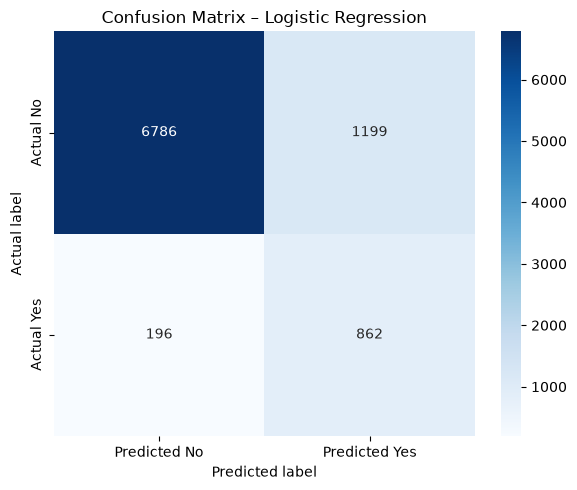

In [18]:
# Choose the best model using F1 as the primary criterion,
# with AUC and MCC as tie-breakers. Review all metrics before finalizing.
ranked_results = results_df.sort_values(
    by=["F1", "AUC", "MCC"], ascending=False
)
best_model_name = ranked_results.iloc[0]["Model"]
best_model = pipelines[best_model_name]

best_predictions = best_model.predict(X_test)

print("Provisional best model:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test, best_predictions,
    labels=[NEGATIVE_LABEL, POSITIVE_LABEL],
    zero_division=0
))

cm = confusion_matrix(
    y_test, best_predictions,
    labels=[NEGATIVE_LABEL, POSITIVE_LABEL]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)
plt.title(f"Confusion Matrix – {best_model_name}")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.show()
